# Transformer VAE latent spaces on the Nature data

A self-attention VAE with the conv VAE's latent, so every score and view of notebooks 02 and 05 applies unchanged
(`ml/common/models/seq_vae.py`, `TransformerVAE`; trainer `ml/nature/awareness/train_vae.py --arch transformer`).

| part | layout |
|---|---|
| tokens | the window cut into 40 patches (5 samples, 25 ms, at 1 s; 15 samples, 75 ms, at 3 s: the patch scales with the window as the conv VAE's pooling does), each embedded linearly with a learned position |
| encoder | 3 pre-norm self-attention layers (width 64, 4 heads), the tokens averaged in 8 groups of 5, 1x1 heads to the mean and log variance: 4 filters x 8 steps |
| decoder | non-autoregressive: the latent mapped to width 64 and interpolated to the 40 tokens, a second learned position, 3 self-attention layers, a linear map from each token back to its patch |
| size | 217 to 251 k parameters, by input (conv VAE 30 to 34 k, LSTM-VAE 107 to 109 k) |
| training | as the conv VAE (AE settings, bf16 autocast, early stopping on the validation negative ELBO) |

**Why it might help**: attention relates every part of the window to every other directly, which a two-stage
convolution only approximates; on 3 s windows that spans two or three strides.

**Runs**: the four inputs of the ablation x β 1, 32, 128 fixed and β 1 learned x three seeds: 48 runs,
`submit.sh --vae --inputs <input> --args "--arch transformer" --array 0-11`, pulled to `runs/vae/xformer_vae_*`. Every
view uses the four validation participants; scores are notebook 05's.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _latent_views as lv
import _vae_runs as vr
import _novelty_scores as ns

ARCH, MODEL_PREFIX, TAG, NB = 'transformer', 'Transformer VAE ·', 'xformer_vae', '04'   # architecture shown here and figure prefix (02 conv, 03 LSTM, 04 Transformer)
RUNS = Path(os.environ.get('HIPEXO_VAE_RUNS', REPO / 'notebooks' / 'nature' / 'model_exploration' / 'runs' / 'vae'))
DATA = REPO / 'data' / 'processed_nature' / 'ae'                              # built by ml/nature/awareness/ae_data.py
VIEW_CACHE = REPO / 'data' / 'cache' / 'nature' / 'vae_views'
SHOWN_SEED = 0
FIG_DIR = Path.cwd() / 'figures'                                            # figures for Live_Update
FIG_DIR.mkdir(exist_ok = True)
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
found = vr.discover_vae_runs(RUNS, ARCH)
HAVE_RUNS = not found.empty
if HAVE_RUNS:
    runs = {r.run: vr.load_vae_run(r.run, tables[r.inputs]) for r in found.itertuples()}
    print(f'{len(found)} runs in {found.groupby(vr.CELL_COLS).ngroups} cells under {RUNS}; '
          f'code {sorted({r["summary"]["git_sha"] for r in runs.values()})}')
    display(found.pivot_table(index = ['inputs', 'decoder_variance'], columns = 'beta', values = 'seed', aggfunc = 'count').fillna(0).astype(int))
else:
    print(f'No finished {ARCH} VAE runs under {RUNS} yet. Run the grid on the cluster and pull it (commands above), then rerun.')

48 runs in 16 cells under /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/nature/model_exploration/runs/vae; code ['248e43c-dirty']


beta                              1.0    32.0   128.0
inputs          decoder_variance                     
raw_1s          fixed                 3      3      3
                learned               3      0      0
raw_1s_spectral fixed                 3      3      3
                learned               3      0      0
raw_3s          fixed                 3      3      3
                learned               3      0      0
raw_3s_spectral fixed                 3      3      3
                learned               3      0      0

## 1. What was trained

Validation participants, familiar windows for training and early stopping; NLL and KL are per window (summed over its
channels and samples, 16 × 200 on 1 s raw input, 23 channels with the spectral features and 600 samples at 3 s, and
over the 32 latent dimensions). A dimension is *active* when its median posterior
variance on the familiar validation windows is below 0.9 (the Science Robotics study's definition).

In [2]:
if HAVE_RUNS:
    cells, per_seed = vr.get_cell_table(runs, found)
    display(cells)
    display(per_seed.round(4))

seeds best epoch val NLL / window val KL / window          val MSE active dims (of 32)    minutes
inputs          decoder_variance beta                                                                                                    
raw_1s          fixed            1.0        3     18 ± 7     3320.3 ± 8.7    69.51 ± 0.54  0.2373 ± 0.0054          32.0 ± 0.0  2.5 ± 0.6
                                 32.0       3     26 ± 9    3504.9 ± 10.7     7.58 ± 0.18  0.3527 ± 0.0067           8.0 ± 0.0  3.2 ± 0.8
                                 128.0      3      9 ± 3     4415.0 ± 7.8     0.00 ± 0.00  0.9215 ± 0.0049           0.0 ± 0.0  1.7 ± 0.3
                learned          1.0        3     17 ± 6    1753.8 ± 22.8   111.15 ± 3.98  0.2461 ± 0.0020          32.0 ± 0.0  2.4 ± 0.5
raw_1s_spectral fixed            1.0        3    31 ± 10     4635.5 ± 5.3    73.18 ± 0.31  0.1775 ± 0.0023          32.0 ± 0.0  3.4 ± 0.9
                                 32.0       3     20 ± 6    4893.9 ± 12.7     8.30 ± 0.25  0.2899 ± 0.0055           8.0 ± 0.0  2.5 ± 0.5
                                 128.0      3     24 ± 4    5035.3 ± 18.5     3.56 ± 0.06  0.3514 ± 0.0081           3.0 ± 0.0  2.8 ± 0.3
                learned          1.0        3    40 ± 16   -356.5 ± 254.2   133.97 ± 2.42  0.1943 ± 0.0033          32.0 ± 0.0  4.3 ± 1.5
raw_3s          fixed            1.0        3     24 ± 6   10292.2 ± 17.6    93.22 ± 2.96  0.3063 ± 0.0037          32.0 ± 0.0  2.8 ± 0.5
                                 32.0       3     24 ± 7   10481.2 ± 25.8    17.03 ± 0.35  0.3457 ± 0.0054          13.7 ± 0.6  2.9 ± 0.6
                                 128.0      3    25 ± 10   10814.5 ± 89.2     6.19 ± 0.18  0.4151 ± 0.0186           7.0 ± 1.7  2.9 ± 0.9
                learned          1.0        3     11 ± 1    6774.7 ± 67.0   124.01 ± 1.07  0.3120 ± 0.0039          32.0 ± 0.0  1.8 ± 0.0
raw_3s_spectral fixed            1.0        3     22 ± 5   14251.9 ± 27.2    99.21 ± 0.31  0.2276 ± 0.0039          32.0 ± 0.0  3.1 ± 0.7
                                 32.0       3     31 ± 6    14557.1 ± 8.4    18.38 ± 0.43  0.2719 ± 0.0012          17.7 ± 2.1  3.6 ± 0.6
                                 128.0      3     25 ± 4   14852.7 ± 22.9     7.30 ± 0.14  0.3147 ± 0.0033           6.0 ± 1.7  3.1 ± 0.3
                learned          1.0        3     36 ± 9    744.7 ± 576.1   151.54 ± 0.57  0.2398 ± 0.0044          32.0 ± 0.0  4.1 ± 0.8

best epoch  val NLL / window  val KL / window  val MSE  active dims (of 32)  minutes
inputs          decoder_variance beta  seed                                                                                      
raw_1s          fixed            1.0   0             23         3311.6692          69.2004   0.2319                   32     2.92
                                       1             22         3320.1648          70.1387   0.2372                   32     2.83
                                       2             10         3329.0500          69.1894   0.2428                   32     1.77
                                 32.0  0             29         3497.9238           7.5899   0.3483                    8     3.42
                                       1             16         3517.2290           7.3989   0.3604                    8     2.32
                                       2             34         3499.4675           7.7515   0.3493                    8     3.90
                                 128.0 0              6         4405.9580           0.0037   0.9158                    0     1.33
                                       1             11         4418.6147           0.0011   0.9238                    0     1.83
                                       2             11         4420.3198           0.0013   0.9248                    0     1.82
                learned          1.0   0             22         1743.9987         113.6975   0.2438                   32     2.82
                                       1             19         1737.6024         113.1863   0.2475                   32     2.55
                                       2             11         1779.8381         106.5589   0.2469                   32     1.85
raw_1s_spectral fixed            1.0   0             30         4634.9644          72.8305   0.1773                   32     3.32
                                       1             21         4641.0195          73.4240   0.1800                   32     2.52
                                       2             41         4630.3931          73.2869   0.1753                   32     4.39
                                 32.0  0             17         4902.0298           8.3261   0.2934                    8     2.22
                                       1             16         4900.3794           8.0380   0.2927                    8     2.15
                                       2             27         4879.2217           8.5394   0.2835                    8     3.09
                                 128.0 0             27         5020.2510           3.5512   0.3448                    3     3.07
                                       1             26         5029.6362           3.6245   0.3489                    3     2.98
                                       2             20         5056.0142           3.5154   0.3604                    3     2.46
                learned          1.0   0             26         -112.4135         131.2130   0.1906                   32     2.94
                                       1             38         -337.3197         134.9487   0.1968                   32     4.12
                                       2             57         -619.7949         135.7566   0.1956                   32     5.85
raw_3s          fixed            1.0   0             31        10286.1240          92.1732   0.3051                   32     3.41
                                       1             19        10311.9541          96.5603   0.3104                   32     2.44
                                       2             22        10278.3975          90.9187   0.3035                   32     2.65
                                 32.0  0             31        10458.7832          17.3559   0.3410                   14     3.51
                                       1             18        10509.4111          16.6654   0.3516                   13     2.37
               

## 2. Training curves

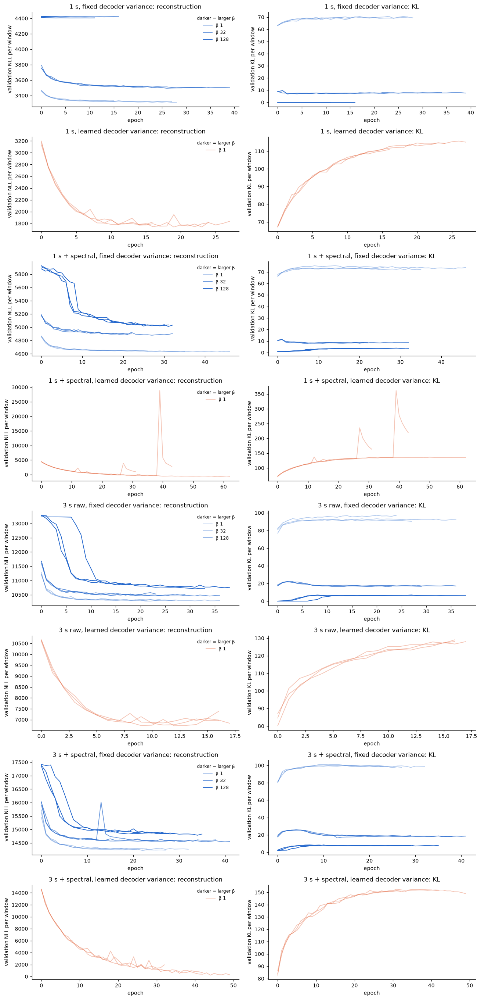

In [3]:
if HAVE_RUNS:
    vr.plot_curves(runs, found)

## 3. How much of the code each VAE uses

Active dimensions and KL against β, per input and decoder variance (compare notebook 02 for the conv VAE).

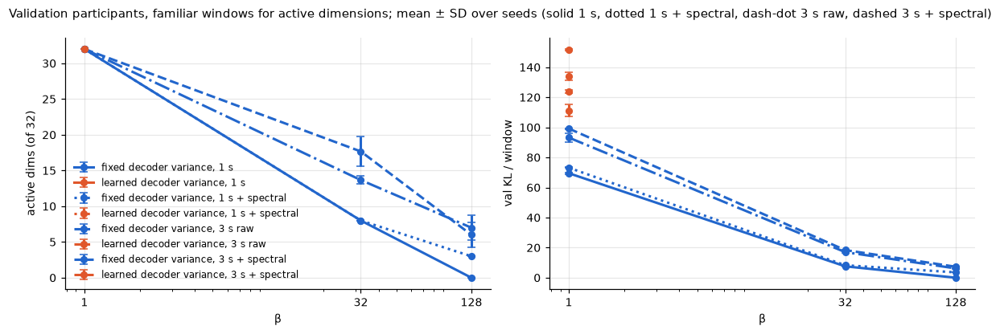

In [4]:
if HAVE_RUNS:
    vr.plot_active_and_kl(per_seed, FIG_DIR / f'{NB}_{TAG}_active_kl.png')

### 3.1 KL per latent dimension

Mean KL of each dimension over the validation participants' windows (seed 0): which of the 32 dimensions carry
information, and whether the same ones survive as β grows. Columns are the 4 filters × 8 time steps.

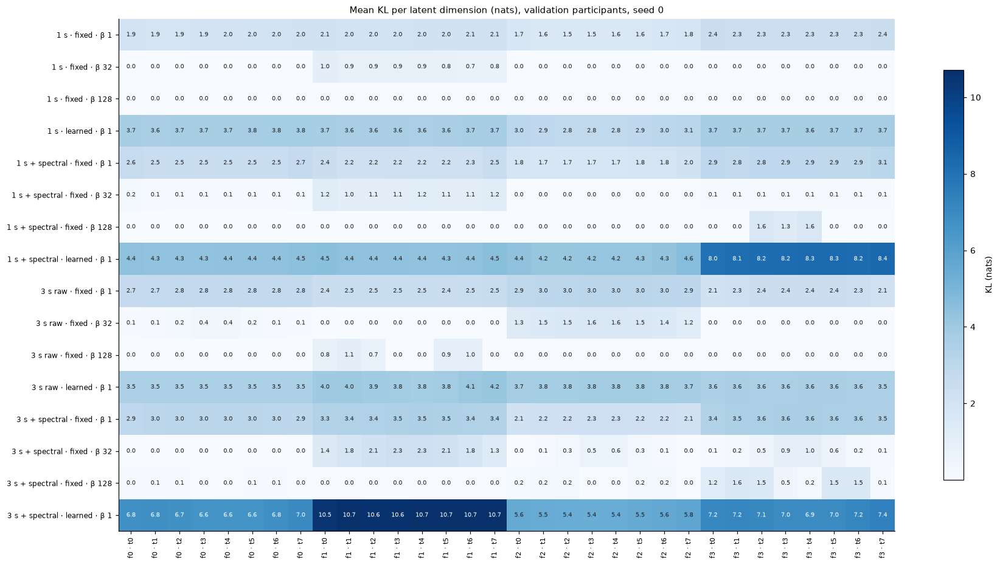

In [5]:
if HAVE_RUNS:
    shown = found[found['seed'] == SHOWN_SEED]
    grid = pd.DataFrame({vr.get_cell_label(r.inputs, r.decoder_variance, r.beta): vr.get_kl_per_dim(runs[r.run]['z'], runs[r.run]['logvar'])
                         for r in shown.itertuples()}).T
    grid.columns = [f'f{u // 8} · t{u % 8}' for u in grid.columns]
    vr.plot_heatmap(grid, f'Mean KL per latent dimension (nats), validation participants, seed {SHOWN_SEED}', 'KL (nats)', '{:.1f}')

## 4. The learned decoder variance

Decoder standard deviation per input channel, in standardized units (1 = the channel's training SD), for the
learned-variance runs: which channels the decoder reconstructs confidently. The fixed-variance runs have 1 everywhere.

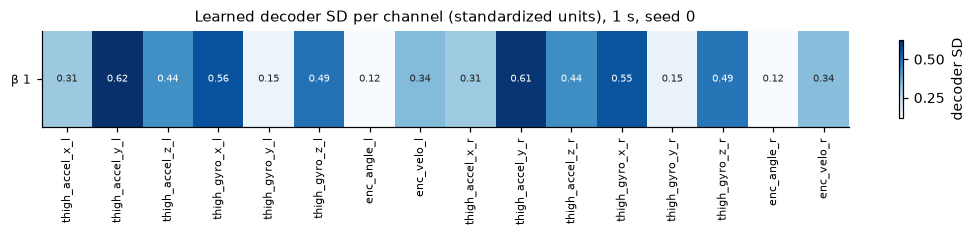

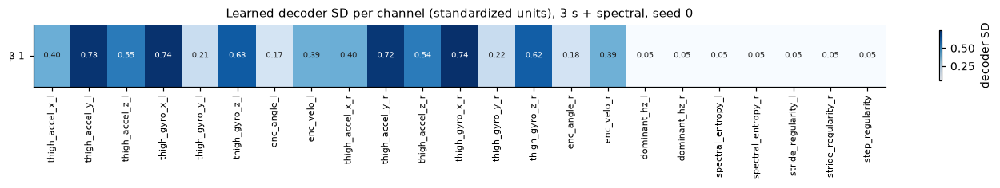

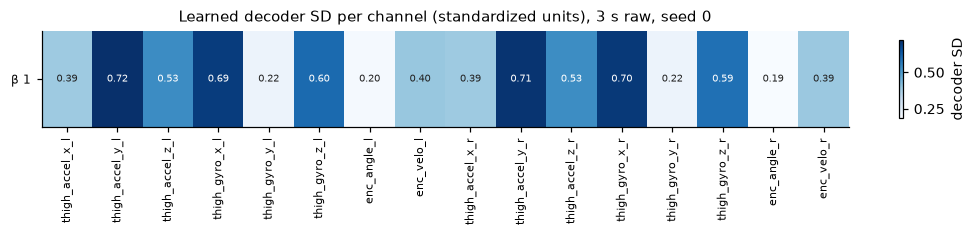

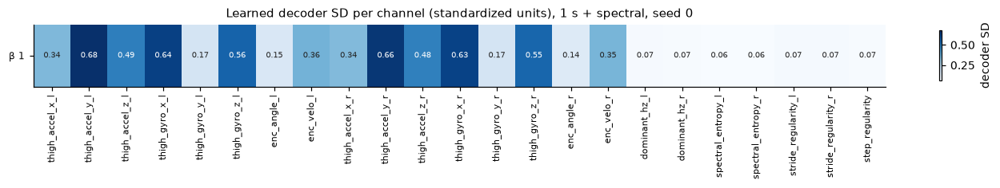

In [6]:
if HAVE_RUNS:
    for inputs, spec in meta['inputs'].items():
        learned = found[(found['decoder_variance'] == 'learned') & (found['seed'] == SHOWN_SEED) & (found['inputs'] == inputs)]
        if learned.empty:
            continue
        channel_names = meta['channels'] + list(spec['features'])
        sigma = pd.DataFrame({f'β {r.beta:g}': runs[r.run]['summary']['decoder_sigma'] for r in learned.itertuples()}, index = channel_names).T
        vr.plot_heatmap(sigma, f'Learned decoder SD per channel (standardized units), {vr.INPUT_SHORT[inputs]}, seed {SHOWN_SEED}', 'decoder SD',
                        '{:.2f}', save = FIG_DIR / f'{NB}_{TAG}_decoder_sigma_{inputs}.png')


## 5. Posterior width by task

Median over each task's validation windows of the mean posterior variance across the run's active dimensions (seed 0).
With the variance fixed, the Science Robotics study found this flat across tasks; this shows whether it still is.
Descriptive only: how well it separates unfamiliar movement is a score, and is notebook 05's.

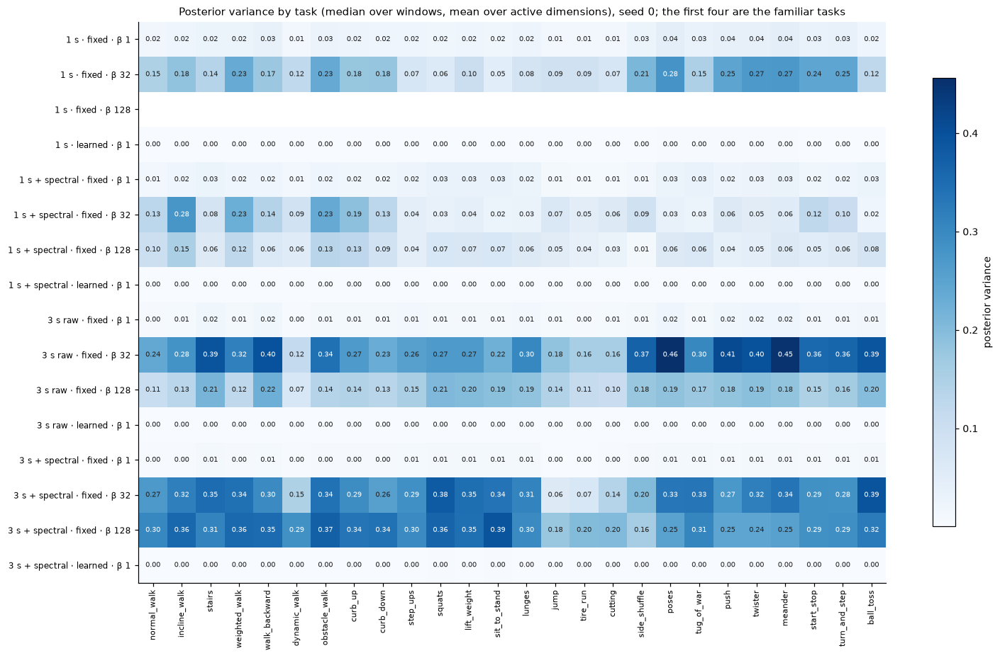

In [7]:
if HAVE_RUNS:
    tasks = list(nt.ID_SAFE_TASKS) + [t for ts in nt.TASK_FAMILIES.values() for t in ts if t not in nt.ID_SAFE_TASKS]
    widths = {}
    for r in shown.itertuples():
        run = runs[r.run]
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        widths[vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)] = vr.get_width_by_task(run['labels'], run['logvar'],
                                                                            vr.get_active(run['logvar'], familiar))
    width = pd.DataFrame(widths).T.reindex(columns = tasks)
    vr.plot_heatmap(width, f'Posterior variance by task (median over windows, mean over active dimensions), seed {SHOWN_SEED}; '
                    'the first four are the familiar tasks', 'posterior variance', '{:.2f}')

## 6. Latent maps

Posterior means of up to 250 validation windows per task (the same windows for every run), on the run's active
dimensions, in the three views of notebook 01 (the highest-variance dimensions, PCA, UMAP), coloured by task family and
by controller class. One row per β for each input and decoder variance, seed 0. The windows are
those every run exported, so 1 s and 3 s models are drawn on the same windows.

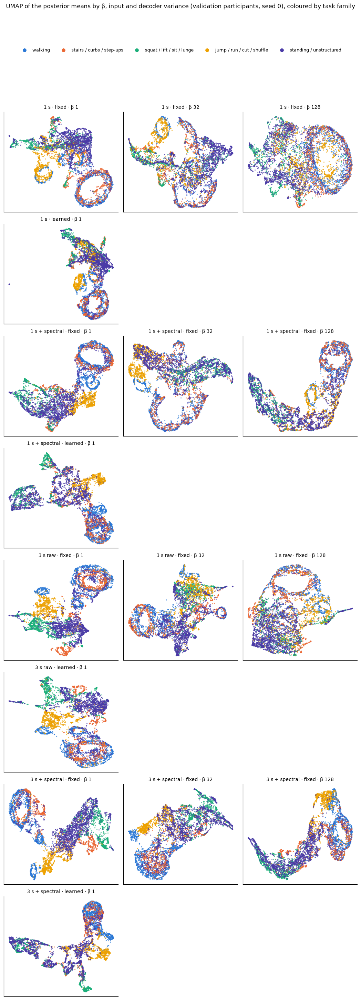

6,500 validation windows, 26 tasks, participants ['BT09', 'BT12', 'BT13', 'BT21']


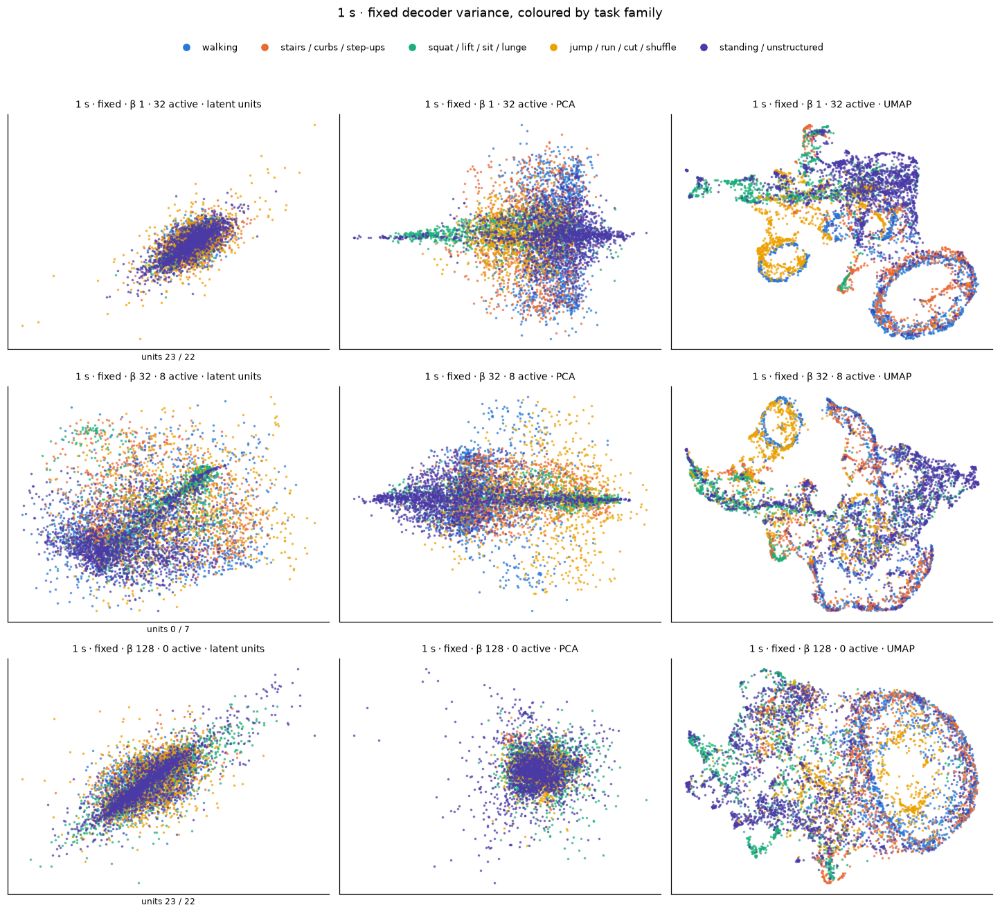

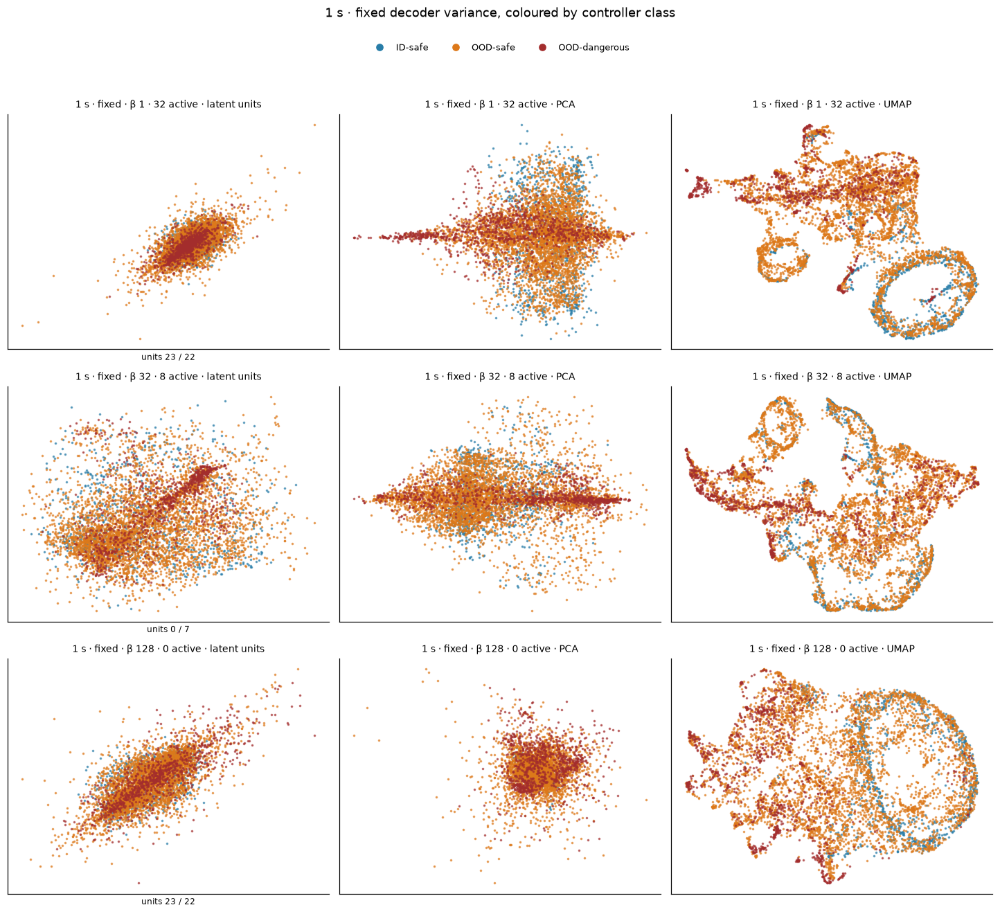

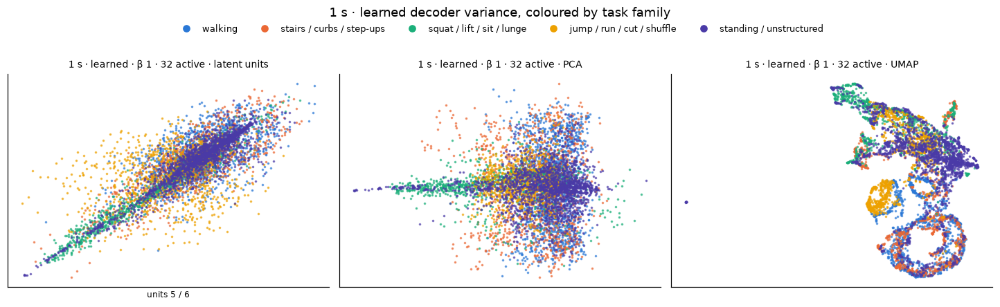

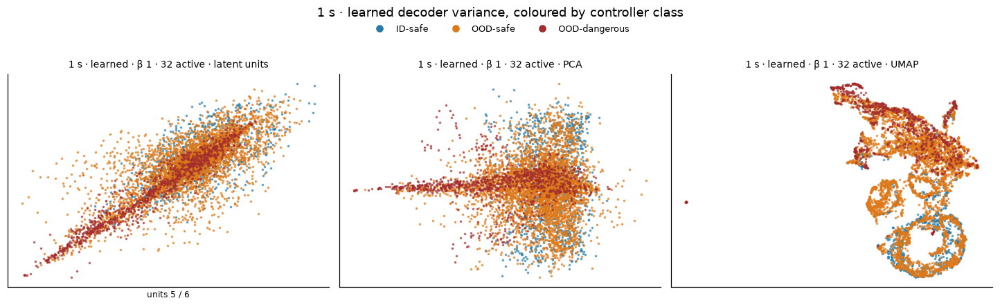

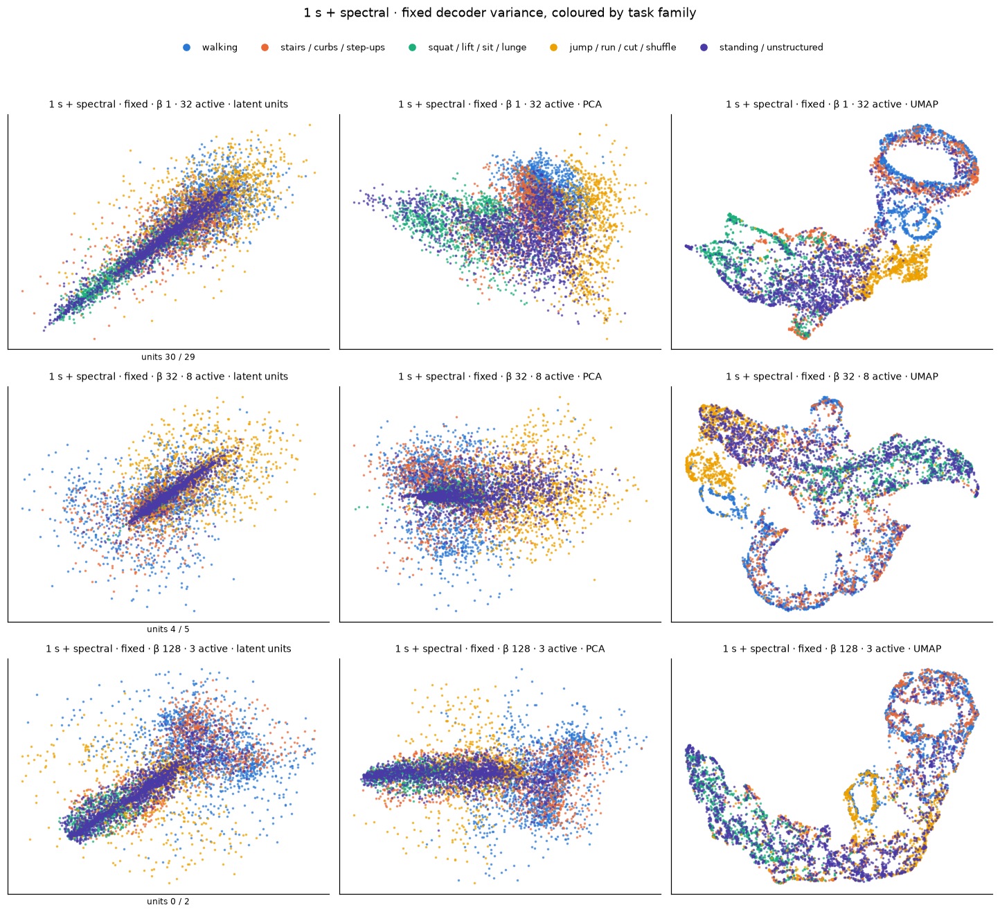

...

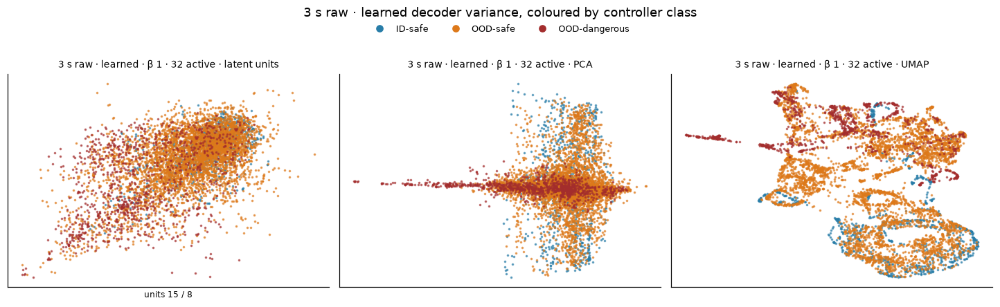

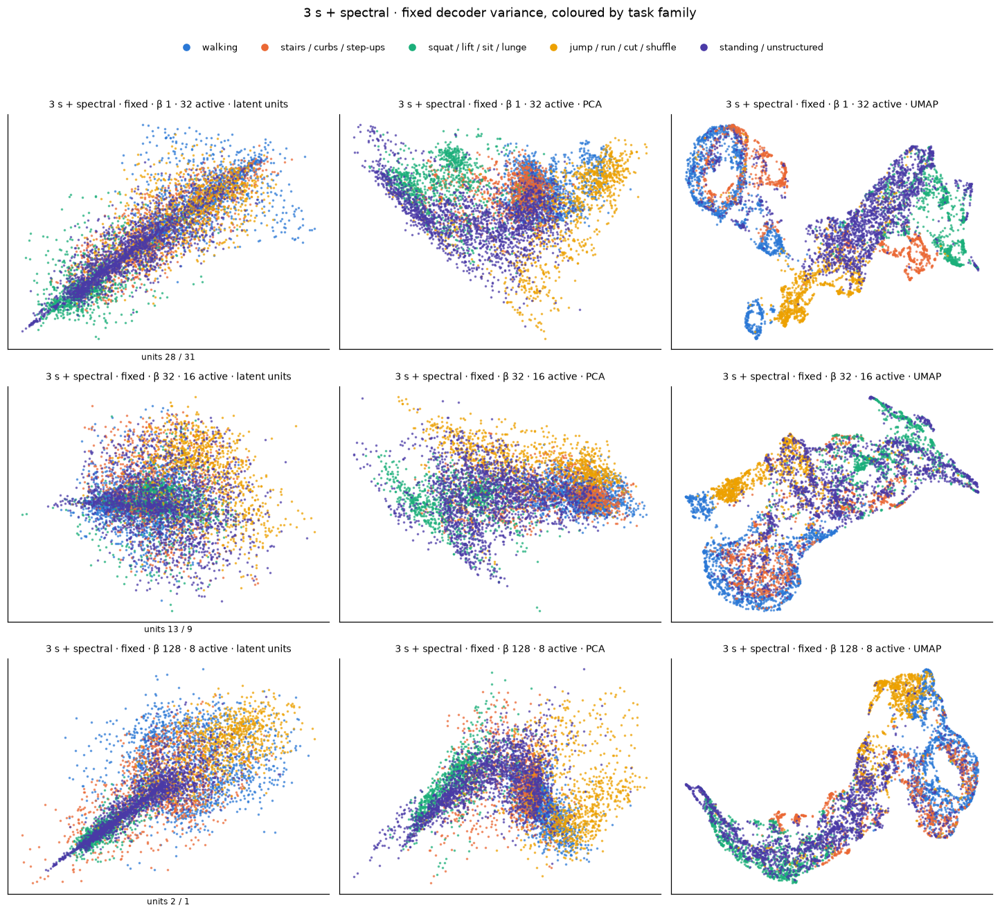

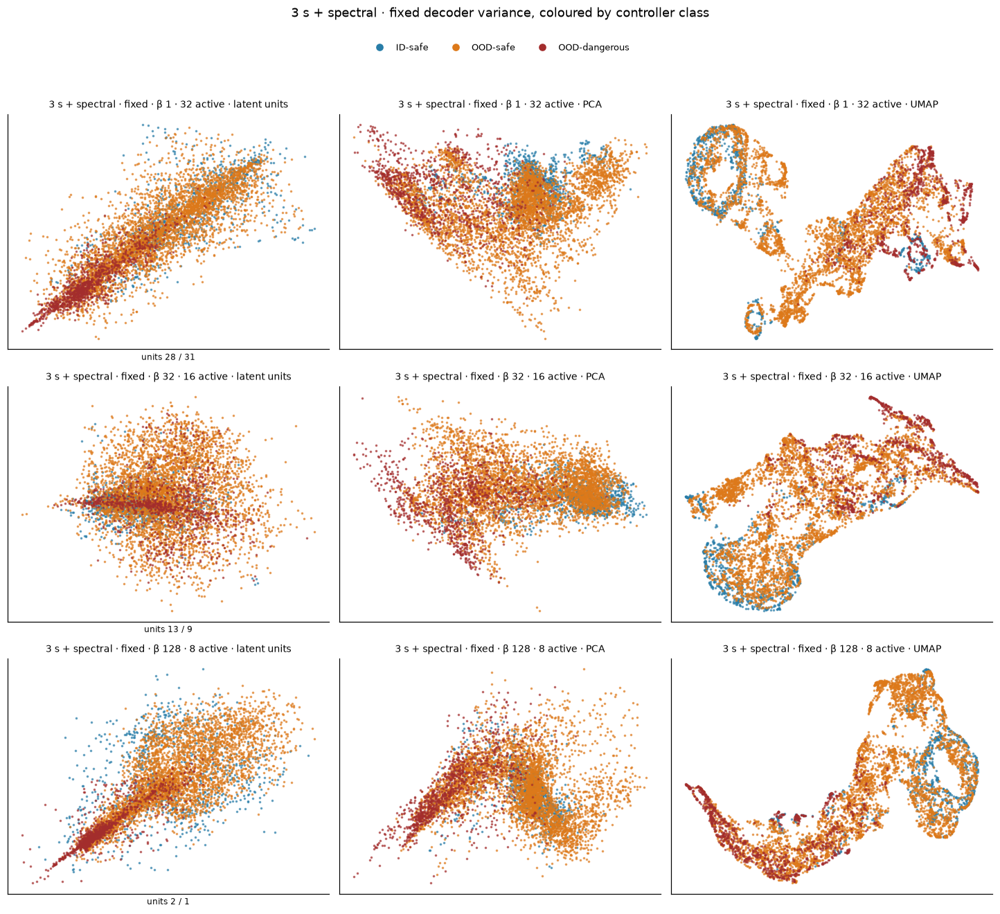

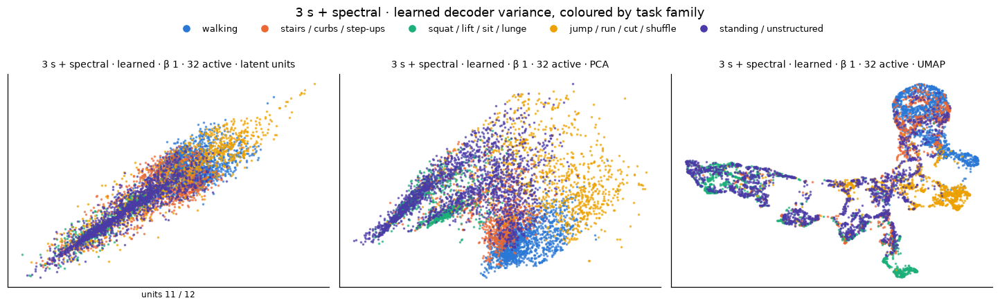

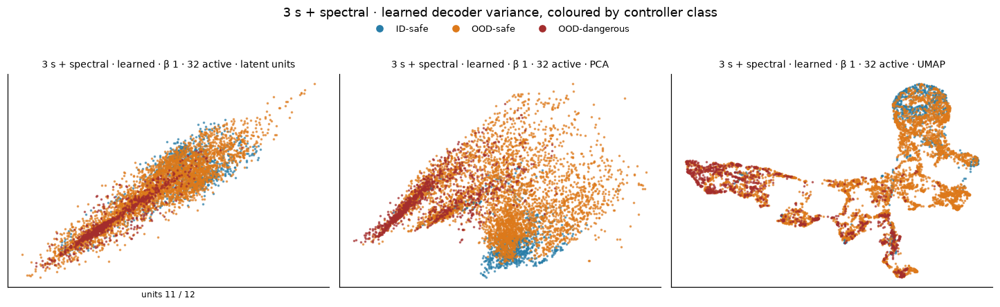

In [8]:
if HAVE_RUNS:
    base = shown.sort_values('inputs', ascending = False).iloc[0]                 # a 3 s run if any: its windows exist in every run
    first = runs[base.run]['labels']
    pick = lv.get_balanced_sample(first, 250, np.random.default_rng(0))
    labels = first.iloc[pick].reset_index(drop = True)
    views, actives = {}, {}
    for r in shown.itertuples():
        run = runs[r.run]
        z = lv.get_aligned_z({'labels': run['labels'], 'z': run['z']}, labels)                  # (N, 32), same windows
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        key = vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)
        views[key], actives[key] = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE), int(active.sum())
    keyed = {(' · '.join(k.split(' · ')[:2]), float(k.split(' · ')[2].removeprefix('β '))): v for k, v in views.items()}
    vr.plot_umap_by_beta(keyed, labels, 'family', lv.FAMILY_C, lv.BACKGROUND, 'UMAP of the posterior means by β, input and decoder variance '
                         f'(validation participants, seed {SHOWN_SEED}), coloured by task family', FIG_DIR / f'{NB}_{TAG}_umap_by_beta.png')
    print(f'{len(labels):,} validation windows, {labels.task.nunique()} tasks, participants {sorted(labels.subject.astype(str).unique())}')
    for group in dict.fromkeys(k[0] for k in keyed):
        part = {f'{k} · {actives[k]} active': v for k, v in views.items() if k.startswith(group + ' ·')}
        lv.plot_lens_grid(part, labels, 'family', lv.FAMILY_C, f'{group} decoder variance, coloured by task family')
        lv.plot_lens_grid(part, labels, 'controller_class', lv.CLASS_C, f'{group} decoder variance, coloured by controller class')


## 7. Interactive 3-D: the best fixed- and learned-variance Transformer VAE

The two cells drawn are chosen in notebook 05 (section 7.2's rule): for each decoder variance, the cell (β and input)
whose best native score has the highest validation AUROC for unfamiliar against familiar windows. Seed 0, the windows of
section 6 (up to 80 per task here), in 3-D; the dropdown switches view and lens. Besides task, family, controller class and
direction, a **KL quartile** lens colours each window by its KL in that run (light = lowest), because at high β the KL
is that model's novelty signal. Standalone copies are saved in `interactive/`.

In [9]:
import re

RESULTS = Path.cwd() / 'results' / '05_native_scores.csv'                    # written by notebook 05, section 7.2
INTERACTIVE = Path.cwd() / 'interactive'
CONFIG_3D = {'scrollZoom': True, 'displaylogo': False}
KL_C = {'1 lowest': '#c6dbef', '2': '#6baed6', '3': '#2171b5', '4 highest': '#08306b'}   # sequential: one hue, light to dark
if HAVE_RUNS and RESULTS.exists():
    native = pd.read_csv(RESULTS)
    native = native[native['family'] == 'vae']
    val_best = native.groupby(['model', 'score'])['val AUROC, unfamiliar vs familiar'].mean().groupby('model').max()
    found['model'] = [ns.get_model_label(r.config, r.stem) for r in found.itertuples()]
    STYLES = lv.get_task_styles(nt.TASK_FAMILIES)
    lenses = {'task': ('task', {t: STYLES[t]['family'] for ts in nt.TASK_FAMILIES.values() for t in ts}),
              'family': ('family', lv.FAMILY_C), 'controller class': ('controller_class', lv.CLASS_C),
              'direction': ('direction', lv.DIRECTION_C), 'KL quartile': ('kl_quartile', KL_C)}
    rng3 = np.random.default_rng(1)
    show = np.sort(np.concatenate([rng3.choice(np.flatnonzero(labels['task'].astype(str).to_numpy() == t),
                                               min(80, int((labels['task'] == t).sum())), replace = False)
                                    for t in labels['task'].astype(str).unique()]))
    for variance in ('fixed', 'learned'):
        candidates = val_best[[m for m in val_best.index if f'{variance} variance' in m and m.startswith(MODEL_PREFIX)]]
        if candidates.empty:
            print(f'no scored {variance}-variance runs of this architecture in {RESULTS.name} yet: run notebook 05 first')
            continue
        model = candidates.idxmax()
        r = found[(found['model'] == model) & (found['seed'] == SHOWN_SEED)].iloc[0]
        run = runs[r.run]
        idx = run['labels'][['rec', 'end']].reset_index().merge(labels[['rec', 'end']], on = ['rec', 'end'], how = 'right')['index'].to_numpy()
        lab3 = labels.copy()
        lab3['kl_quartile'] = pd.qcut(run['kl'][idx], 4, labels = list(KL_C)).astype(str)
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        z = run['z'][idx]
        v3 = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE)
        name = f'{model} (validation AUROC {candidates.max():.3f})'
        fig = lv.build_3d({name: {k: v[show] for k, v in v3.items() if k != 'units'}}, lab3.iloc[show].reset_index(drop = True),
                          lenses, {t: s['symbol'] for t, s in STYLES.items()}, name)
        INTERACTIVE.mkdir(exist_ok = True)
        path = INTERACTIVE / f'{TAG}_best_{variance}_3d.html'
        fig.write_html(path, include_plotlyjs = 'cdn', config = CONFIG_3D)
        fig.show(config = CONFIG_3D)
        print(f'best {variance}-variance cell: {model}; standalone copy {path.relative_to(REPO)}')
elif HAVE_RUNS:
    print('Run notebook 05 first: it writes results/05_native_scores.csv, which picks the cells shown here.')

best fixed-variance cell: Transformer VAE · β 1 · fixed variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/xformer_vae_best_fixed_3d.html


best learned-variance cell: Transformer VAE · β 1 · learned variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/xformer_vae_best_learned_3d.html


## 8. What this shows

The latent spaces only; detection is notebook 05's (section 9 there: on 3 s raw this model reaches test AUROC 0.949 for
unfamiliar and 0.985 for OOD-dangerous windows, second to the LSTM-VAE).

- **At β 1 it uses its whole code and reconstructs best.** All 32 dimensions are active on every input (1, 3), its KL is
  the highest of the three architectures on three inputs (70 nats per window on 1 s and 93 on 3 s raw, against 60 and 81
  for the conv VAE; level with the LSTM-VAE on 3 s + spectral), and its reconstruction error is the lowest on every input (0.237 on 1 s, against 0.246 for the conv VAE and 0.282
  for the LSTM-VAE).
- **β prunes it like the conv VAE, except that β 128 collapses it on 1 s raw windows.** There the KL is zero in all three
  seeds and the reconstruction error (0.92) is that of an output that ignores the window. Elsewhere β 32 keeps 8
  dimensions on 1 s inputs and 14 to 18 on 3 s, and β 128 keeps 3 to 7 (3).
- **On 3 s raw at β 128 its KL is a downward novelty score**, as the conv VAE's is on 1 s: 0.888 for unfamiliar and 0.836
  for OOD-dangerous windows in notebook 05, with 7 dimensions left. With the spectral features the KL reads upward
  instead, in every architecture, wherever it is above chance.
- **Posterior width:** at β 32 on 3 s raw the unstructured standing tasks have the widest posteriors (poses 0.46, meander
  0.45, push 0.41, twister 0.40) and the vigorous ones the narrowest (jumping, running, cutting and dynamic walking, 0.12
  to 0.18), against 0.24 to 0.39 for the familiar tasks (5). Quiet unfamiliar movement is wider, as in the LSTM-VAE, but
  within reach of the familiar range; at β 1 every width is below 0.05.
- **Its raw latents are the closest of any VAE's to the plain autoencoder's** (linear CKA 0.76 on 1 s and 0.68 on 3 s,
  notebook 05, section 9.4), and its maps look alike (6): gait rings for walking and stairs, loops for jumping and running,
  the standing tasks in the middle on 1 s, the families further apart on 3 s raw. Attention over 40 patches learns much
  the same code as the convolutions.
- **The tightest learned decoder of the three.** The least-trusted axes sit at 0.55 to 0.74 of their SD (0.68 to 0.91 for
  the other architectures), the sagittal channels at 0.12 to 0.22, and every spectral channel at 0.05 to 0.07, where the
  conv and LSTM decoders leave one or two loose (4).
- **The 3-D pages** (7): β 1 on 3 s raw for both decoder variances; the fixed-variance cell is this architecture's best
  detector.